In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision
from sklearn.metrics import confusion_matrix
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split 
import math
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
print("Tải dữ liệu và tính toán thông số chuẩn hóa...")

# Bước 1: Tải tập dữ liệu thô để tính mean và std chính xác (đã chia 255)
raw_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
raw_data_normalized = raw_train.data.float() / 255.0

pixel_mean = raw_data_normalized.mean().item()
pixel_std = raw_data_normalized.std().item()

print(f"Pixel Mean tính toán động: {pixel_mean:.4f}")
print(f"Pixel Std tính toán động: {pixel_std:.4f}")

# Bước 2: Tạo bộ transform động chuẩn hoá dữ liệu dựa trên mean và std tính toán
dynamic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((pixel_mean,), (pixel_std,))
])

# Bước 3: Khởi tạo Dataset với transform chuẩn
train_dataset_original = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=dynamic_transform
)
test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=dynamic_transform
)
train_size = int(0.9 * len(train_dataset_original))  # 54.000 mẫu
val_size = len(train_dataset_original) - train_size   # 6.000 mẫu
# Bước 4: Tạo DataLoader
batch_size = 64
train_dataset, val_dataset = random_split(train_dataset_original, [train_size, val_size])

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

def to_one_hot(y, num_classes=10):
    """Chuyển đổi nhãn indices thành ma trận một-hot dạng Float32 an toàn."""
    one_hot = torch.zeros(y.size(0), num_classes, device=y.device, dtype=torch.float32)
    one_hot[range(y.size(0)), y] = 1.0
    return one_hot


Tải dữ liệu và tính toán thông số chuẩn hóa...
Pixel Mean tính toán động: 0.1307
Pixel Std tính toán động: 0.3081


In [3]:
class MultilayerPerceptron:
    def __init__(self, input_dim=784, hidden_dim=128, num_classes=10, lr=0.001):
        self.lr = lr
        
        # --- Khởi tạo Trọng số tầng ẩn (Layer 1) sử dụng He (Kaiming) Initialization cho ReLU ---
        bound1 = math.sqrt(2.0 / input_dim)
        self.W1 = torch.randn(input_dim, hidden_dim) * bound1
        self.b1 = torch.zeros(1, hidden_dim)
        
        # --- Khởi tạo Trọng số tầng đầu ra (Layer 2) sử dụng Xavier cho Softmax ---
        bound2 = math.sqrt(6.0 / (hidden_dim + num_classes))
        self.W2 = (torch.rand(hidden_dim, num_classes) * 2 * bound2) - bound2
        self.b2 = torch.zeros(1, num_classes)
        
        # Bộ nhớ Cache lưu các giá trị trung gian cho quá trình Backward
        self.cache = {}
        
        # Khởi tạo các biến chứa Gradients toàn cục
        self.dW1, self.db1 = None, None
        self.dW2, self.db2 = None, None

    def forward(self, X):
        # Flatten ảnh về (Batch_size, 784)
        X = X.reshape(X.size(0), -1).float()
        
        # TẦNG ẨN (LAYER 1): Tuyến tính + Kích hoạt ReLU
        Z1 = torch.matmul(X, self.W1) + self.b1
        A1 = torch.clamp(Z1, min=0.0) # ReLU activation: max(0, Z1)
        
        # TẦNG ĐẦU RA (LAYER 2): Tuyến tính + Kích hoạt Softmax
        Z2 = torch.matmul(A1, self.W2) + self.b2
        
        # Ổn định số học cho Softmax
        max_z2 = torch.max(Z2, dim=1, keepdim=True)[0]
        exp_z2 = torch.exp(Z2 - max_z2)
        Y_hat = exp_z2 / torch.sum(exp_z2, dim=1, keepdim=True)
        
        # Lưu trữ tất cả các trạng thái kích hoạt vào cache
        self.cache = {'X': X, 'Z1': Z1, 'A1': A1, 'Y_hat': Y_hat}
        return Y_hat

    def backward(self, Y):
        # Lấy lại các giá trị từ cache
        X = self.cache['X']
        Z1 = self.cache['Z1']
        A1 = self.cache['A1']
        Y_hat = self.cache['Y_hat']
        
        m = Y.size(0)
        Y_one_hot = to_one_hot(Y, num_classes=Y_hat.size(1))
        
        # --- ĐẠO HÀM TẦNG 2 (Output Layer) ---
        dZ2 = (Y_hat - Y_one_hot) / m
        self.dW2 = torch.matmul(A1.t(), dZ2)
        self.db2 = torch.utils.data.dataloader.torch.sum(dZ2, dim=0, keepdim=True)
        
        # --- ĐẠO HÀM TẦNG 1 (Hidden Layer với ReLU) ---
        # Đạo hàm lan truyền ngược qua ma trận trọng số W2
        dA1 = torch.matmul(dZ2, self.W2.t())
        
        # Đạo hàm đi qua hàm kích hoạt ReLU: bằng dA1 nếu Z1 > 0, ngược lại bằng 0
        dZ1 = dA1.clone()
        dZ1[Z1 <= 0] = 0.0
        
        # Tính toán Gradients cho W1 và b1
        self.dW1 = torch.matmul(X.t(), dZ1)
        self.db1 = torch.sum(dZ1, dim=0, keepdim=True)

    def optimize_step(self):
        # Cập nhật đồng thời trọng số của cả 2 tầng (Gradient Descent)
        self.W1 -= self.lr * self.dW1
        self.b1 -= self.lr * self.db1
        self.W2 -= self.lr * self.dW2
        self.b2 -= self.lr * self.db2


In [4]:
# =====================================================================
# (TRAINING & TEST)
# =====================================================================
# Khởi tạo mạng MLP với 128 nút ẩn, học phí lr = 0.001
model = MultilayerPerceptron(input_dim=784, hidden_dim=128, num_classes=10, lr=0.001)
epochs = 10

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

print("Quá trình huấn luyện mô hình MLP...")
print("-" * 60)

for epoch in range(epochs):
    # ----------------- TRAIN PHASE -----------------
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        Y_hat = model.forward(images)
        
        batch_size = labels.size(0)
        prob_correct_class = Y_hat[range(batch_size), labels]
        loss = -torch.sum(torch.log(prob_correct_class + 1e-9)) / batch_size
        running_loss += loss.item()
        
        _, predicted = torch.max(Y_hat, dim=1)
        total_train += batch_size
        correct_train += (predicted == labels).sum().item()
        
        model.backward(labels)
        model.optimize_step()
        
    epoch_train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    # ----------------- TEST PHASE -----------------
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for val_images, val_labels in val_loader:
            Y_hat_val = model.forward(val_images)

            t_batch_size = val_labels.size(0)
            prob_correct_class_val = Y_hat_val[range(t_batch_size), val_labels]
            val_loss = -torch.sum(torch.log(prob_correct_class_val + 1e-9)) / t_batch_size
            running_val_loss += val_loss.item()

            _, val_predicted = torch.max(Y_hat_val, dim=1)
            total_val += t_batch_size
            correct_val += (val_predicted == val_labels).sum().item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct_val / total_val

    # Ghi lịch sử chỉ số
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(train_accuracy)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(val_accuracy)

    print(f"Epoch [{epoch + 1}/{epochs}]")
    print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {train_accuracy:.2f}%")
    print(f"  [Validation ] Loss: {epoch_val_loss:.4f} | Accuracy: {val_accuracy:.2f}%")
    print("-" * 60)

print("Mô hình MLP đã huấn luyện xong thành công!")

Quá trình huấn luyện mô hình MLP...
------------------------------------------------------------
Epoch [1/10]
  [Train] Loss: 1.1843 | Accuracy: 63.99%
  [Validation ] Loss: 0.7065 | Accuracy: 79.80%
------------------------------------------------------------
Epoch [2/10]
  [Train] Loss: 0.5991 | Accuracy: 83.31%
  [Validation ] Loss: 0.5180 | Accuracy: 84.97%
------------------------------------------------------------
Epoch [3/10]
  [Train] Loss: 0.4783 | Accuracy: 86.62%
  [Validation ] Loss: 0.4428 | Accuracy: 87.18%
------------------------------------------------------------
Epoch [4/10]
  [Train] Loss: 0.4203 | Accuracy: 88.14%
  [Validation ] Loss: 0.3998 | Accuracy: 88.42%
------------------------------------------------------------
Epoch [5/10]
  [Train] Loss: 0.3843 | Accuracy: 89.16%
  [Validation ] Loss: 0.3712 | Accuracy: 89.07%
------------------------------------------------------------
Epoch [6/10]
  [Train] Loss: 0.3588 | Accuracy: 89.87%
  [Validation ] Loss: 0.3502

In [5]:
#Test phase: Đánh giá mô hình trên tập test
running_test_loss = 0.0
correct_test = 0
total_test = 0

all_true_labels = []
all_pred_labels = []

with torch.no_grad():
    for test_images, test_labels in test_loader:
        t_batch_size = test_labels.size(0)
        
        Y_hat_test = model.forward(test_images)
        Y_hat_test_cpu = Y_hat_test.cpu()
        test_labels_cpu = test_labels.cpu()

        prob_correct_class_test = Y_hat_test_cpu[range(t_batch_size), test_labels_cpu]
        test_loss_step = -torch.sum(torch.log(prob_correct_class_test + 1e-9)) / t_batch_size
        running_test_loss += test_loss_step.item()

        _, test_predicted = torch.max(Y_hat_test_cpu, dim=1)
        total_test += t_batch_size
        correct_test += (test_predicted == test_labels_cpu).sum().item()
        
        all_true_labels.extend(test_labels_cpu.numpy().tolist())
        all_pred_labels.extend(test_predicted.numpy().tolist())

# Tính toán các chỉ số trung bình sau khi duyệt qua toàn bộ tập test
final_test_loss = running_test_loss / len(test_loader)
final_test_accuracy = 100 * correct_test / total_test

print(f"\n[KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST]")
print(f"  > Final Test Loss: {final_test_loss:.4f}")
print(f"  > Final Test Accuracy: {final_test_accuracy:.2f}%")


[KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST]
  > Final Test Loss: 0.2833
  > Final Test Accuracy: 91.57%


In [6]:
history['final_test_loss'] = final_test_loss
history['final_test_acc'] = final_test_accuracy

#  Tích hợp dữ liệu mảng nhãn thực tế và dự đoán để vẽ Ma trận nhầm lẫn
history['confusion_matrix'] = {
    'true_labels': all_true_labels,
    'pred_labels': all_pred_labels
}

# Ghi toàn bộ dictionary vào file JSON cấu trúc rõ ràng (indent=4)
json_filename = "nlp_classifier_results.json"
with open(json_filename, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

print(f"Hệ thống đã lưu lịch sử chỉ số và dữ liệu ma trận nhầm lẫn vào file thành công!")
print(f"  > Tên file kết quả: '{json_filename}'")

Hệ thống đã lưu lịch sử chỉ số và dữ liệu ma trận nhầm lẫn vào file thành công!
  > Tên file kết quả: 'nlp_classifier_results.json'


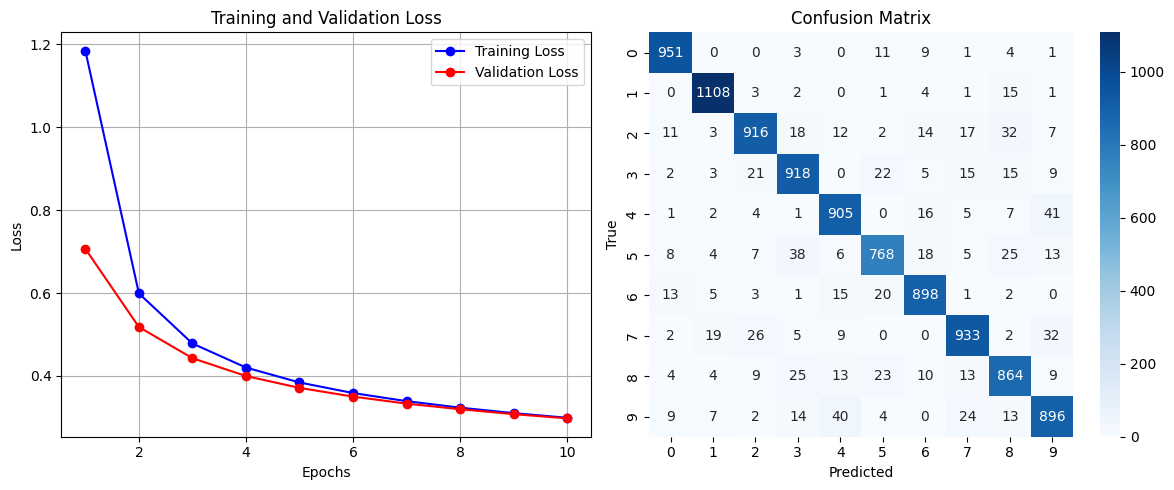

Đã vẽ và lưu đồ thị thành công vào file 'softmax_classifier_plots.png'!


In [8]:
json_filename = "nlp_classifier_results.json"
with open(json_filename, "w" if False else "r", encoding="utf-8") as f:
    data = json.load(f)

epochs = range(1, len(data['train_loss']) + 1)

#  Vẽ biểu đồ Training Loss vs Validation Loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, data['train_loss'], 'b-o', label='Training Loss')
plt.plot(epochs, data['val_loss'], 'r-o', label='Validation Loss') 
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Tính toán và vẽ Ma trận nhầm lẫn (Confusion Matrix)
true_labels = data['confusion_matrix']['true_labels']
pred_labels = data['confusion_matrix']['pred_labels']
cm = confusion_matrix(true_labels, pred_labels)

plt.subplot(1, 2, 2)
# Tạo nhãn từ 0 đến 9 cho MNIST
classes = [str(i) for i in range(10)]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.tight_layout()
# Lưu hình ảnh đồ thị ra file (🌟 Thay đổi tên file lưu cho đúng mô hình)
output_image = 'softmax_classifier_plots.png'
plt.savefig(output_image, dpi=300)
plt.show()

print(f"Đã vẽ và lưu đồ thị thành công vào file '{output_image}'!")